# Thực hành: Cây quyết định và Rừng cây (Bài toán 1 – 2.1.2)
**Dữ liệu:** Default of Credit Card Clients (Kaggle) – dự đoán khách hàng có vỡ nợ tháng tới hay không (`default payment next month`).

**Nội dung**
- Nhiệm vụ 1: Xây dựng cây quyết định (`max_depth=2`) và trực quan hoá bằng graphviz
- Nhiệm vụ 2: Tìm `max_depth` tối ưu bằng `GridSearchCV`, vẽ biểu đồ đánh giá
- Nhiệm vụ 3: Xây dựng Random Forest, tìm `n_estimators` tối ưu, xem feature importance

## Bước 1. Import thư viện

In [1]:
import numpy as np                  # tính toán số học
import pandas as pd                 # xử lý dữ liệu
import matplotlib.pyplot as plt     # vẽ biểu đồ
%matplotlib inline
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 120    # (bài mẫu dùng 400, giảm xuống để file nhẹ hơn)
import graphviz                     # vẽ cây quyết định

## Bước 2. Nạp và làm sạch dữ liệu
File `data.csv` trong bài mẫu là bản **đã làm sạch** từ file gốc. Vì ta dùng file gốc từ Kaggle nên cần làm sạch các bước sau:
1. Đổi tên cột `PAY_0` → `PAY_1` (file gốc đặt tên thiếu `PAY_1`).
2. Gộp các giá trị không hợp lệ của `EDUCATION` (0, 5, 6) vào nhóm 4 = "others".
3. Loại các dòng `MARRIAGE = 0` (giá trị không có trong mô tả dữ liệu).
4. Loại các cột không dùng: `ID`, `SEX`, `PAY_2`…`PAY_6` (như danh sách `items_to_remove` của bài mẫu).

In [2]:
df = pd.read_csv('default_of_credit_card_clients.csv')
print('Kích thước ban đầu:', df.shape)
print('ID trùng lặp:', df['ID'].duplicated().sum(), '| Giá trị thiếu:', df.isna().sum().sum())

df = df.rename(columns={'PAY_0': 'PAY_1'})
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})
df = df[df['MARRIAGE'] != 0].reset_index(drop=True)
print('Kích thước sau làm sạch:', df.shape)
df.head()

Kích thước ban đầu: (30000, 25)
ID trùng lặp: 0 | Giá trị thiếu: 0
Kích thước sau làm sạch: (29946, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
features_response = df.columns.tolist()

# Các cột cần loại bỏ (không phải feature hoặc không liên quan)
items_to_remove = ['ID', 'SEX', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6',
                   'EDUCATION_CAT', 'graduate school', 'high school', 'none',
                   'others', 'university']
features_response = [item for item in features_response if item not in items_to_remove]
features_response

['LIMIT_BAL',
 'EDUCATION',
 'MARRIAGE',
 'AGE',
 'PAY_1',
 'BILL_AMT1',
 'BILL_AMT2',
 'BILL_AMT3',
 'BILL_AMT4',
 'BILL_AMT5',
 'BILL_AMT6',
 'PAY_AMT1',
 'PAY_AMT2',
 'PAY_AMT3',
 'PAY_AMT4',
 'PAY_AMT5',
 'PAY_AMT6',
 'default payment next month']

In [4]:
print('Tỉ lệ vỡ nợ:', df['default payment next month'].mean().round(4))
df['default payment next month'].value_counts()

Tỉ lệ vỡ nợ: 0.2214


default payment next month
0    23315
1     6631
Name: count, dtype: int64

## Bước 3. Chia tập train / test (80% / 20%)

In [5]:
from sklearn.model_selection import train_test_split
from sklearn import tree

# features_response[:-1] là các feature, phần tử cuối là nhãn
X_train, X_test, y_train, y_test = train_test_split(
    df[features_response[:-1]].values,
    df['default payment next month'].values,
    test_size=0.2, random_state=24)
print(X_train.shape, X_test.shape)

(23956, 17) (5990, 17)


---
# Nhiệm vụ 1: Xây dựng cây quyết định bằng Scikit-Learn

In [6]:
# Cây phát triển tối đa đến độ sâu 2
dt = tree.DecisionTreeClassifier(max_depth=2)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

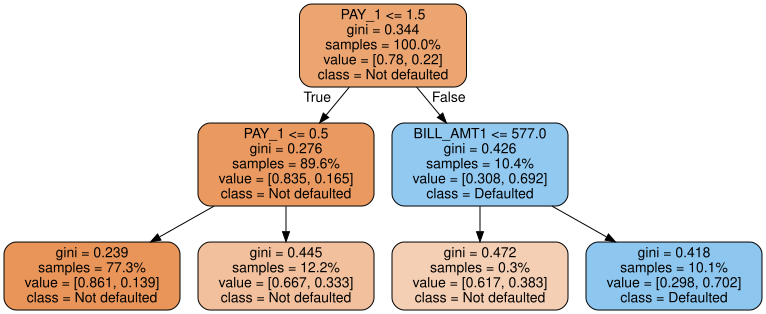

In [7]:
dot_data = tree.export_graphviz(dt,
                                out_file=None,
                                filled=True,
                                rounded=True,
                                feature_names=features_response[:-1],
                                proportion=True,
                                class_names=['Not defaulted', 'Defaulted'])
graph = graphviz.Source(dot_data)
graph

**Nhận xét:** Nút gốc tách theo `PAY_1 <= 1.5` (tình trạng thanh toán tháng gần nhất). Nhánh *True* (đa số khách hàng) có tỉ lệ vỡ nợ thấp, nhánh *False* có tỉ lệ vỡ nợ cao hơn rõ rệt. `PAY_1` là đặc trưng phân biệt mạnh nhất.

---
# Nhiệm vụ 2: Tìm tham số tối ưu cho cây quyết định bằng GridSearchCV
- `scoring='roc_auc'`: dùng diện tích dưới đường ROC (phù hợp khi dữ liệu mất cân bằng).
- `cv=4`: kiểm định chéo 4 phần (4-fold cross-validation).
- `return_train_score=True`: giữ điểm train để so sánh với điểm test, từ đó đánh giá **bias / variance**.

In [8]:
from sklearn.model_selection import GridSearchCV

params = {'max_depth': [1, 2, 4, 6, 8, 10, 12]}
dt = tree.DecisionTreeClassifier()
cv = GridSearchCV(dt, param_grid=params, scoring='roc_auc',
                  n_jobs=None, refit=True, cv=4, verbose=1,
                  error_score=np.nan, return_train_score=True)
cv.fit(X_train, y_train)

Fitting 4 folds for each of 7 candidates, totalling 28 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.

In [9]:
cv_results_df = pd.DataFrame(cv.cv_results_)
print(cv_results_df.columns.tolist())
print('Tham số tốt nhất:', cv.best_params_, '| ROC AUC (CV):', round(cv.best_score_, 4))
cv_results_df[['param_max_depth', 'mean_train_score', 'mean_test_score']]

['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time', 'param_max_depth', 'params', 'split0_test_score', 'split1_test_score', 'split2_test_score', 'split3_test_score', 'mean_test_score', 'std_test_score', 'rank_test_score', 'split0_train_score', 'split1_train_score', 'split2_train_score', 'split3_train_score', 'mean_train_score', 'std_train_score']
Tham số tốt nhất: {'max_depth': 6} | ROC AUC (CV): 0.7475


,param_max_depth,mean_train_score,mean_test_score
0,1,0.643338,0.643338
1,2,0.697310,0.697232
2,4,0.748952,0.738251
3,6,0.773896,0.747496
4,8,0.802881,0.736755
5,10,0.842870,0.709200
6,12,0.886021,0.674495


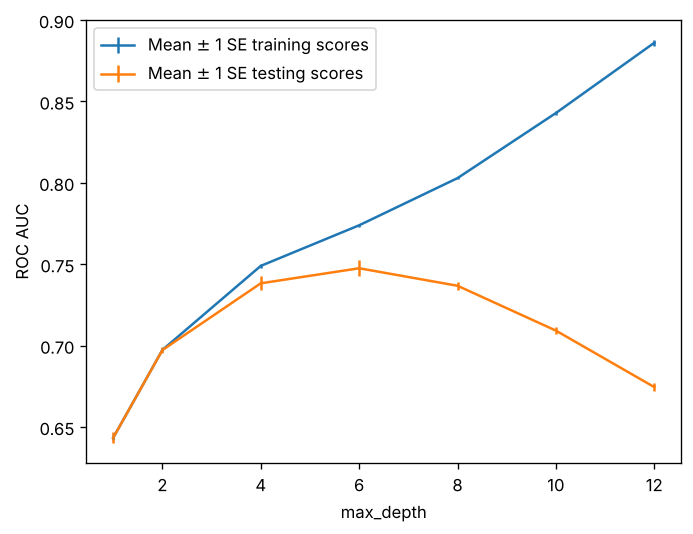

In [10]:
ax = plt.axes()
ax.errorbar(cv_results_df['param_max_depth'],
            cv_results_df['mean_train_score'],
            yerr=cv_results_df['std_train_score']/np.sqrt(4),
            label='Mean $\\pm$ 1 SE training scores')
ax.errorbar(cv_results_df['param_max_depth'],
            cv_results_df['mean_test_score'],
            yerr=cv_results_df['std_test_score']/np.sqrt(4),
            label='Mean $\\pm$ 1 SE testing scores')
ax.legend()
plt.xlabel('max_depth')
plt.ylabel('ROC AUC')
plt.show()

**Nhận xét:** Điểm train tăng liên tục khi cây sâu hơn, nhưng điểm test đạt đỉnh quanh `max_depth` ≈ 4–6 rồi giảm → cây quá sâu bị **quá khớp (overfitting)**: bias giảm nhưng variance tăng. Nên chọn độ sâu ở vùng điểm test cao nhất.

---
# Nhiệm vụ 3: Xây dựng rừng cây (Random Forest)

In [11]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=10, criterion='gini', max_depth=3,
    min_samples_split=2, min_samples_leaf=1, min_weight_fraction_leaf=0.0,
    max_features='sqrt', max_leaf_nodes=None, min_impurity_decrease=0.0,
    bootstrap=True, oob_score=False, n_jobs=None,
    random_state=4, verbose=0, warm_start=False, class_weight=None)

In [12]:
# Lưới tham số: số cây từ 10 đến 100, bước 10
rf_params_ex = {'n_estimators': list(range(10, 110, 10))}
cv_rf_ex = GridSearchCV(rf, param_grid=rf_params_ex,
                        scoring='roc_auc', n_jobs=None,
                        refit=True, cv=4, verbose=1,
                        error_score=np.nan,   # lưu ý: np.nan, không phải chuỗi 'np.nan'
                        return_train_score=True)
cv_rf_ex.fit(X_train, y_train)

Fitting 4 folds for each of 10 candidates, totalling 40 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...andom_state=4)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_estimators': [10, 20, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be

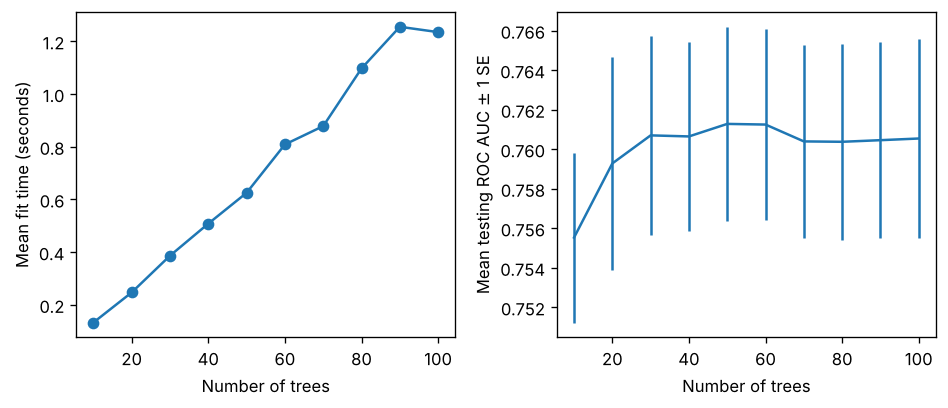

In [13]:
cv_rf_ex_results_df = pd.DataFrame(cv_rf_ex.cv_results_)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(8, 3.5))
axs[0].plot(cv_rf_ex_results_df['param_n_estimators'],
            cv_rf_ex_results_df['mean_fit_time'], '-o')
axs[0].set_xlabel('Number of trees')
axs[0].set_ylabel('Mean fit time (seconds)')

axs[1].errorbar(cv_rf_ex_results_df['param_n_estimators'],
                cv_rf_ex_results_df['mean_test_score'],
                yerr=cv_rf_ex_results_df['std_test_score']/np.sqrt(4))
axs[1].set_xlabel('Number of trees')
axs[1].set_ylabel('Mean testing ROC AUC $\\pm$ 1 SE')
plt.tight_layout()
plt.show()

**Nhận xét:** Thời gian huấn luyện tăng gần tuyến tính theo số cây, trong khi ROC AUC tăng nhanh rồi gần như phẳng. Thêm cây sau ngưỡng đó chỉ tốn thời gian mà không cải thiện đáng kể.

Tham số tốt nhất: {'n_estimators': 50}
ROC AUC (CV): 0.7613


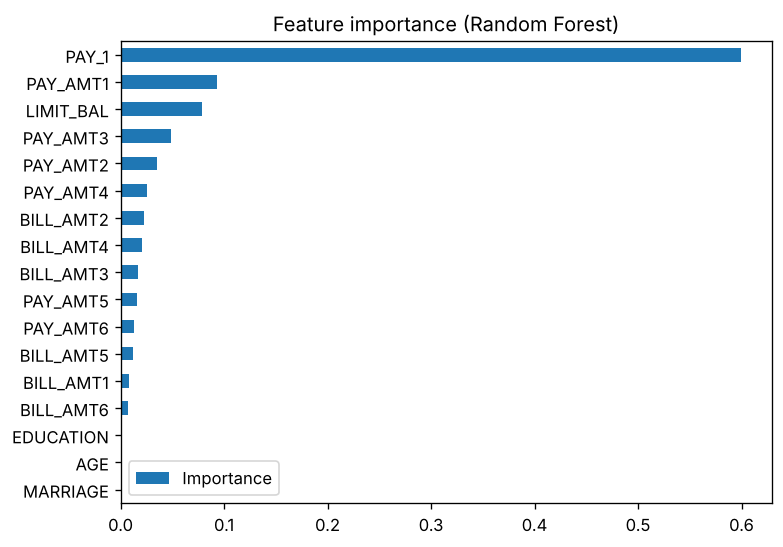

In [14]:
print('Tham số tốt nhất:', cv_rf_ex.best_params_)
print('ROC AUC (CV):', round(cv_rf_ex.best_score_, 4))

feat_imp_df = pd.DataFrame(
    {'Importance': cv_rf_ex.best_estimator_.feature_importances_},
    index=features_response[:-1])
feat_imp_df.sort_values('Importance', ascending=True).plot.barh(figsize=(7, 5))
plt.title('Feature importance (Random Forest)')
plt.show()

**Nhận xét:** `PAY_1` áp đảo về mức độ quan trọng, tiếp theo là các đặc trưng về số tiền thanh toán (`PAY_AMT1`, …) và hạn mức tín dụng (`LIMIT_BAL`). `AGE`, `MARRIAGE`, `EDUCATION` đóng góp rất ít.

---
# Đánh giá cuối cùng trên tập test
Bài mẫu chỉ dừng ở điểm cross-validation; ở đây ta đánh giá thêm mô hình tốt nhất trên **tập test** chưa từng thấy.

In [15]:
from sklearn.metrics import roc_auc_score, accuracy_score, classification_report

best_dt = cv.best_estimator_
best_rf = cv_rf_ex.best_estimator_

for name, model in [('Decision Tree', best_dt), ('Random Forest', best_rf)]:
    proba = model.predict_proba(X_test)[:, 1]
    print(f'{name:14s} | ROC AUC test = {roc_auc_score(y_test, proba):.4f} '
          f'| Accuracy = {accuracy_score(y_test, model.predict(X_test)):.4f}')

print()
print(classification_report(y_test, best_rf.predict(X_test),
                            target_names=['Not defaulted', 'Defaulted']))

Decision Tree  | ROC AUC test = 0.7562 | Accuracy = 0.8202
Random Forest  | ROC AUC test = 0.7714 | Accuracy = 0.8109

               precision    recall  f1-score   support

Not defaulted       0.82      0.98      0.89      4638
    Defaulted       0.74      0.25      0.37      1352

     accuracy                           0.81      5990
    macro avg       0.78      0.61      0.63      5990
 weighted avg       0.80      0.81      0.77      5990



## Kết luận
- `PAY_1` là đặc trưng quan trọng nhất trong dự đoán vỡ nợ.
- Cây quyết định đơn dễ quá khớp khi tăng độ sâu; cần chọn `max_depth` bằng cross-validation.
- Random Forest ổn định hơn và thường cho ROC AUC cao hơn cây đơn nhờ giảm phương sai.